Import required libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Project root directory
PROJECT_ROOT = Path.cwd().parent

# Raw dataset directory
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"

# List Excel files
files = list(RAW_DATA_PATH.glob("*.xlsx"))

print("Dataset files found:")

for file in files:
    print(file.name)

Dataset files found:
All_Features_threshold90.xlsx
Data_Dictionary.xlsx
Mapping_File.xlsx


In [7]:
features_df = pd.read_excel(
    RAW_DATA_PATH / "All_Features_threshold90.xlsx"
)

mapping_df = pd.read_excel(
    RAW_DATA_PATH / "Mapping_File.xlsx"
)

dictionary_df = pd.read_excel(
    RAW_DATA_PATH / "Data_Dictionary.xlsx"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [8]:
print("FEATURE DATASET:", features_df.shape)
print("MAPPING DATASET:", mapping_df.shape)
print("DATA DICTIONARY:", dictionary_df.shape)

FEATURE DATASET: (15358, 73)
MAPPING DATASET: (15358, 3)
DATA DICTIONARY: (72, 8)


In [9]:
print("Total columns:", len(features_df.columns))

print("\nColumn names:")

for index, column in enumerate(features_df.columns, start=1):
    print(f"{index}. {column}")

Total columns: 73

Column names:
1. serial_number
2. url
3. label
4. brand_subdomain
5. brand_substring_domain
6. brand_typo_dom
7. fake_tld
8. brand_in_path_query
9. dots_path
10. url_more_than_mean
11. domain_more_than_mean
12. gibberish
13. domain_length
14. url_length
15. url_contains_ip
16. presence_of_url_shortner
17. special_characters_count
18. no_of_at
19. no_of_comma
20. no_of_dollar
21. no_of_semicolon
22. no_of_space
23. no_of_ampersand
24. no_of_dots
25. no_of_equal
26. no_of_percent
27. no_of_underscore
28. no_of_hyphen
29. no_of_questionmark
30. no_of_colon
31. no_of_slashes_inpath
32. has_asterisk
33. has_or
34. has_embedded_url
35. uses_https
36. num_query_params
37. numeric_proportion
38. url_entropy
39. hostname_digit_ratio
40. has_redirections
41. has_punycode
42. count_www
43. count_com
44. url_has_high_risk_extension
45. has_explicit_port
46. total_words_url
47. average_length_of_words
48. longest_word_length
49. shortest_word_length
50. presence_of_free_hosting
5

In [ ]:
#Inspect the first five records
features_df.head()

,serial_number,url,label,brand_subdomain,brand_substring_domain,brand_typo_dom,fake_tld,brand_in_path_query,dots_path,url_more_than_mean,...,suspicious_inline_js,is_footer_mismatch,is_header_mismatch,is_copyright_mismatch,is_socials_mismatch,is_favicon_mismatch,has_missing_title,title_mismatch_with_domain,has_inline_event_handlers,form_action_external
0,2,https://www.google.com.hk/,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
1,4,http://bongacams.com/,0,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
2,6,https://www.tmall.com/,0,0,0,0,0,0,0,0,...,1,0,0,1,0,1,0,0,0,1
3,7,https://www.youth.cn/,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
4,8,https://coccoc.com/,0,0,0,0,0,0,0,0,...,1,0,1,1,0,0,0,1,0,0


In [11]:
#Inspect data types 
features_df.dtypes

serial_number                 int64
url                             str
label                         int64
brand_subdomain               int64
brand_substring_domain        int64
                              ...  
is_favicon_mismatch           int64
has_missing_title             int64
title_mismatch_with_domain    int64
has_inline_event_handlers     int64
form_action_external          int64
Length: 73, dtype: object

In [12]:
# Get complete dataset summary
features_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15358 entries, 0 to 15357
Data columns (total 73 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   serial_number                  15358 non-null  int64  
 1   url                            15358 non-null  str    
 2   label                          15358 non-null  int64  
 3   brand_subdomain                15358 non-null  int64  
 4   brand_substring_domain         15358 non-null  int64  
 5   brand_typo_dom                 15358 non-null  int64  
 6   fake_tld                       15358 non-null  int64  
 7   brand_in_path_query            15358 non-null  int64  
 8   dots_path                      15358 non-null  int64  
 9   url_more_than_mean             15358 non-null  int64  
 10  domain_more_than_mean          15358 non-null  int64  
 11  gibberish                      15358 non-null  int64  
 12  domain_length                  15358 non-null  int64  
 1

In [13]:
# Explore data dictionary
dictionary_df.head(10)

,Feature ID,Feature Name,Data Type,Category,Description,Computational Rule/Threshold/Criteria,Values for the sample URL:https://amazon-login.example.test/account/netflix/verify?id=123,Unnamed: 7
0,F1,brand_subdomain,Boolean (0/1),Brand-jacking,Presence of a brand in the subdomain,"Components of a URL (subdomain, domain, top le...",1.0,NaN
1,F2,brand_substring_domain,Boolean (0/1),Brand-jacking,Presence of a brand as substring in the domain,NaN,0.0,NaN
2,F3,brand_typo_dom,Boolean (0/1),Brand-jacking,Presence of a misspelt brand in the domain,NaN,0.0,NaN
3,F4,fake_tld,Boolean (0/1),Brand-jacking,Presence of a brand with fake top-level domain,NaN,0.0,NaN
4,F5,brand_in_path_query,Boolean (0/1),Brand-jacking,Presence of a brand in the path or query,NaN,1.0,NaN
5,F₆,dots_path,Numerical (count-based),URL-based,Count of dots in the path of URL,NaN,0.0,NaN
6,F₇,url_more_than_mean,Boolean (0/1),URL-based,URL length greater than mean length of phishin...,Mean length of all the phishing urls is comput...,1.0,NaN
7,F₈,domain_more_than_mean,Boolean (0/1),URL-based,Domain length greater than mean length of phis...,Mean length of all the phishing domains is com...,1.0,NaN
8,F₉,gibberish,Boolean (0/1),URL-based,Presence of a nonsense word of length greater ...,Hostname evaluated using the provided pre-trai...,0.0,NaN
9,F₁₀,domain_length,Numerical (integer),URL-based,Length of the domain,NaN,25.0,NaN


In [14]:
dictionary_df.columns

Index(['Feature ID', 'Feature Name', 'Data Type', 'Category', 'Description',
       'Computational Rule/Threshold/Criteria',
       'Values for the sample URL:https://amazon-login.example.test/account/netflix/verify?id=123',
       'Unnamed: 7'],
      dtype='str')

In [15]:
#understand target variable
print(features_df["label"].value_counts())

label
0    8154
1    7204
Name: count, dtype: int64


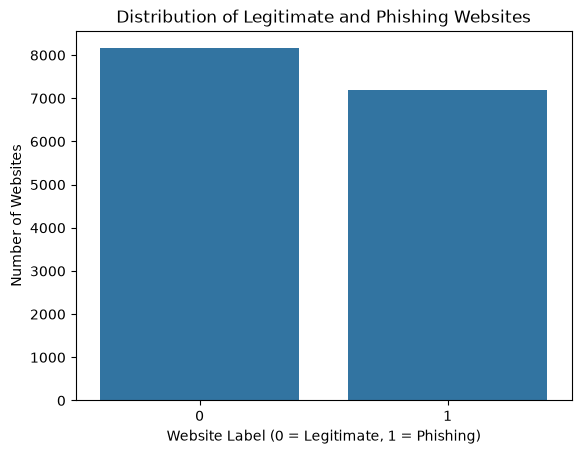

In [16]:
#Visualize distribution
sns.countplot(data=features_df, x="label")

plt.title("Distribution of Legitimate and Phishing Websites")
plt.xlabel("Website Label (0 = Legitimate, 1 = Phishing)")
plt.ylabel("Number of Websites")

plt.show()

In [17]:
# Exclude identifier and target columns
excluded_columns = ["serial_number", "label"]

feature_columns = [
    col for col in features_df.columns
    if col not in excluded_columns + ["url"]
]

# Identify numerical features
numeric_features = features_df[feature_columns].select_dtypes(
    include=np.number
).columns.tolist()

print("Total ML features:", len(feature_columns))
print("Numerical features:", len(numeric_features))

print("\nData types:")
print(features_df[feature_columns].dtypes.value_counts())

Total ML features: 70
Numerical features: 70

Data types:
int64      65
float64     5
Name: count, dtype: int64


In [18]:
binary_features = [
    col for col in numeric_features
    if set(features_df[col].dropna().unique()).issubset({0, 1})
]

print("Total binary features:", len(binary_features))
print("\nBinary features:")

for col in binary_features:
    print(col)

Total binary features: 36

Binary features:
brand_subdomain
brand_substring_domain
brand_typo_dom
fake_tld
brand_in_path_query
url_more_than_mean
domain_more_than_mean
gibberish
url_contains_ip
presence_of_url_shortner
no_of_at
no_of_dollar
no_of_space
has_asterisk
has_or
has_embedded_url
uses_https
has_redirections
has_punycode
url_has_high_risk_extension
has_explicit_port
presence_of_free_hosting
Risky_extensions_In_Html
presence_of_shorten_url_html
hidden_elements_html
Script_loaded_from_ext_domain
suspicious_inline_js
is_footer_mismatch
is_header_mismatch
is_copyright_mismatch
is_socials_mismatch
is_favicon_mismatch
has_missing_title
title_mismatch_with_domain
has_inline_event_handlers
form_action_external


In [19]:
non_binary_features = [
    col for col in numeric_features
    if col not in binary_features
]

print("Non-binary numerical features:", len(non_binary_features))

for col in non_binary_features:
    print(col)

Non-binary numerical features: 34
dots_path
domain_length
url_length
special_characters_count
no_of_comma
no_of_semicolon
no_of_ampersand
no_of_dots
no_of_equal
no_of_percent
no_of_underscore
no_of_hyphen
no_of_questionmark
no_of_colon
no_of_slashes_inpath
num_query_params
numeric_proportion
url_entropy
hostname_digit_ratio
count_www
count_com
total_words_url
average_length_of_words
longest_word_length
shortest_word_length
no_of_forms
no_of_Images
no_of_hyperlinks
no_of_external_links
no_of_internal_links
no_of_null_links
no_of_selfreference_links
no_of_empty_links
EmptyToExternalLinksRatio


In [20]:
feature_summary = features_df[numeric_features].describe().T

feature_summary

,count,mean,std,min,25%,50%,75%,max
brand_subdomain,15358.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
brand_substring_domain,15358.0,0.004363,0.065907,0.0,0.0,0.0,0.0,1.0
brand_typo_dom,15358.0,0.008920,0.094029,0.0,0.0,0.0,0.0,1.0
fake_tld,15358.0,0.000716,0.026754,0.0,0.0,0.0,0.0,1.0
brand_in_path_query,15358.0,0.005014,0.070632,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...
is_favicon_mismatch,15358.0,0.272041,0.445025,0.0,0.0,0.0,1.0,1.0
has_missing_title,15358.0,0.070517,0.256025,0.0,0.0,0.0,0.0,1.0
title_mismatch_with_domain,15358.0,0.675544,0.468187,0.0,0.0,1.0,1.0,1.0
has_inline_event_handlers,15358.0,0.135890,0.342683,0.0,0.0,0.0,0.0,1.0


In [21]:
dictionary_df[
    [
        "Feature ID",
        "Feature Name",
        "Data Type",
        "Category",
        "Description"
    ]
].head(15)

,Feature ID,Feature Name,Data Type,Category,Description
0,F1,brand_subdomain,Boolean (0/1),Brand-jacking,Presence of a brand in the subdomain
1,F2,brand_substring_domain,Boolean (0/1),Brand-jacking,Presence of a brand as substring in the domain
2,F3,brand_typo_dom,Boolean (0/1),Brand-jacking,Presence of a misspelt brand in the domain
3,F4,fake_tld,Boolean (0/1),Brand-jacking,Presence of a brand with fake top-level domain
4,F5,brand_in_path_query,Boolean (0/1),Brand-jacking,Presence of a brand in the path or query
5,F₆,dots_path,Numerical (count-based),URL-based,Count of dots in the path of URL
6,F₇,url_more_than_mean,Boolean (0/1),URL-based,URL length greater than mean length of phishin...
7,F₈,domain_more_than_mean,Boolean (0/1),URL-based,Domain length greater than mean length of phis...
8,F₉,gibberish,Boolean (0/1),URL-based,Presence of a nonsense word of length greater ...
9,F₁₀,domain_length,Numerical (integer),URL-based,Length of the domain


## 3. Feature Quality Analysis

In [22]:
# Find features with only one unique value

constant_features = [
    col for col in feature_columns
    if features_df[col].nunique() == 1
]

print("Number of constant features:", len(constant_features))
print("\nConstant features:")

for col in constant_features:
    print(col, "=", features_df[col].iloc[0])

Number of constant features: 1

Constant features:
brand_subdomain = 0


In [23]:
# Calculate percentage of zeros and ones

binary_summary = pd.DataFrame({
    "Zero_Count": (features_df[binary_features] == 0).sum(),
    "One_Count": (features_df[binary_features] == 1).sum()
})

binary_summary["One_Percentage"] = (
    binary_summary["One_Count"] / len(features_df) * 100
)

binary_summary = binary_summary.sort_values(
    by="One_Percentage"
)

binary_summary

,Zero_Count,One_Count,One_Percentage
brand_subdomain,15358,0,0.000000
has_or,15357,1,0.006511
no_of_dollar,15353,5,0.032556
has_asterisk,15352,6,0.039068
has_punycode,15349,9,0.058601
url_contains_ip,15347,11,0.071624
fake_tld,15347,11,0.071624
has_embedded_url,15337,21,0.136737
has_redirections,15323,35,0.227894
no_of_at,15300,58,0.377653


In [24]:
# Compare average feature values by label

class_comparison = features_df.groupby("label")[numeric_features].mean().T

class_comparison.columns = [
    "Legitimate",
    "Phishing"
]

class_comparison["Difference"] = (
    class_comparison["Phishing"] -
    class_comparison["Legitimate"]
)

class_comparison["Absolute_Difference"] = (
    class_comparison["Difference"].abs()
)

class_comparison = class_comparison.sort_values(
    by="Absolute_Difference",
    ascending=False
)

class_comparison.head(20)

,Legitimate,Phishing,Difference,Absolute_Difference
no_of_hyperlinks,288.930096,27.149917,-261.780179,261.780179
no_of_internal_links,183.046480,8.997640,-174.048840,174.048840
no_of_external_links,98.118224,16.313992,-81.804232,81.804232
no_of_Images,55.927152,7.069267,-48.857885,48.857885
url_length,29.350135,52.186147,22.836012,22.836012
domain_length,12.850748,26.986396,14.135648,14.135648
longest_word_length,9.347682,17.107440,7.759758,7.759758
no_of_null_links,7.765391,1.838284,-5.927107,5.927107
no_of_selfreference_links,5.605347,1.093976,-4.511371,4.511371
average_length_of_words,4.010239,6.090247,2.080008,2.080008


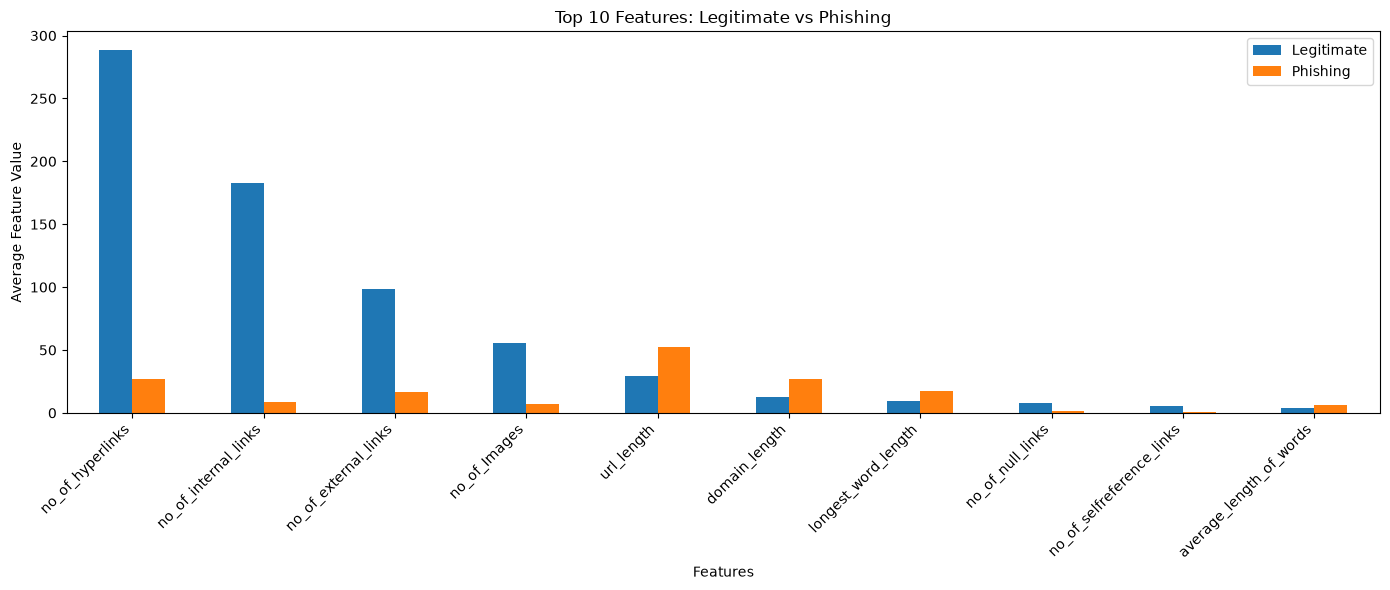

In [25]:
top_features = class_comparison.head(10).index

comparison_plot = features_df.groupby("label")[top_features].mean().T

comparison_plot.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Top 10 Features: Legitimate vs Phishing")
plt.xlabel("Features")
plt.ylabel("Average Feature Value")
plt.xticks(rotation=45, ha="right")
plt.legend(["Legitimate", "Phishing"])
plt.tight_layout()
plt.show()

## 3.2 Binary Feature Analysis by Class

In [26]:
#Compare binary features between classes
binary_class_comparison = features_df.groupby("label")[
    binary_features
].mean().T

binary_class_comparison.columns = [
    "Legitimate",
    "Phishing"
]

binary_class_comparison["Difference"] = (
    binary_class_comparison["Phishing"] -
    binary_class_comparison["Legitimate"]
)

binary_class_comparison["Absolute_Difference"] = (
    binary_class_comparison["Difference"].abs()
)

binary_class_comparison = binary_class_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
)

binary_class_comparison

,Legitimate,Phishing,Difference,Absolute_Difference
domain_more_than_mean,0.005764,0.421433,0.415668,0.415668
title_mismatch_with_domain,0.486019,0.890061,0.404042,0.404042
Script_loaded_from_ext_domain,0.744910,0.378262,-0.366648,0.366648
hidden_elements_html,0.576159,0.248195,-0.327963,0.327963
is_copyright_mismatch,0.641771,0.956968,0.315197,0.315197
url_more_than_mean,0.036424,0.323431,0.287008,0.287008
presence_of_free_hosting,0.000858,0.272904,0.272045,0.272045
is_header_mismatch,0.314202,0.114797,-0.199404,0.199404
url_has_high_risk_extension,0.009934,0.183232,0.173298,0.173298
is_footer_mismatch,0.233505,0.077041,-0.156464,0.156464


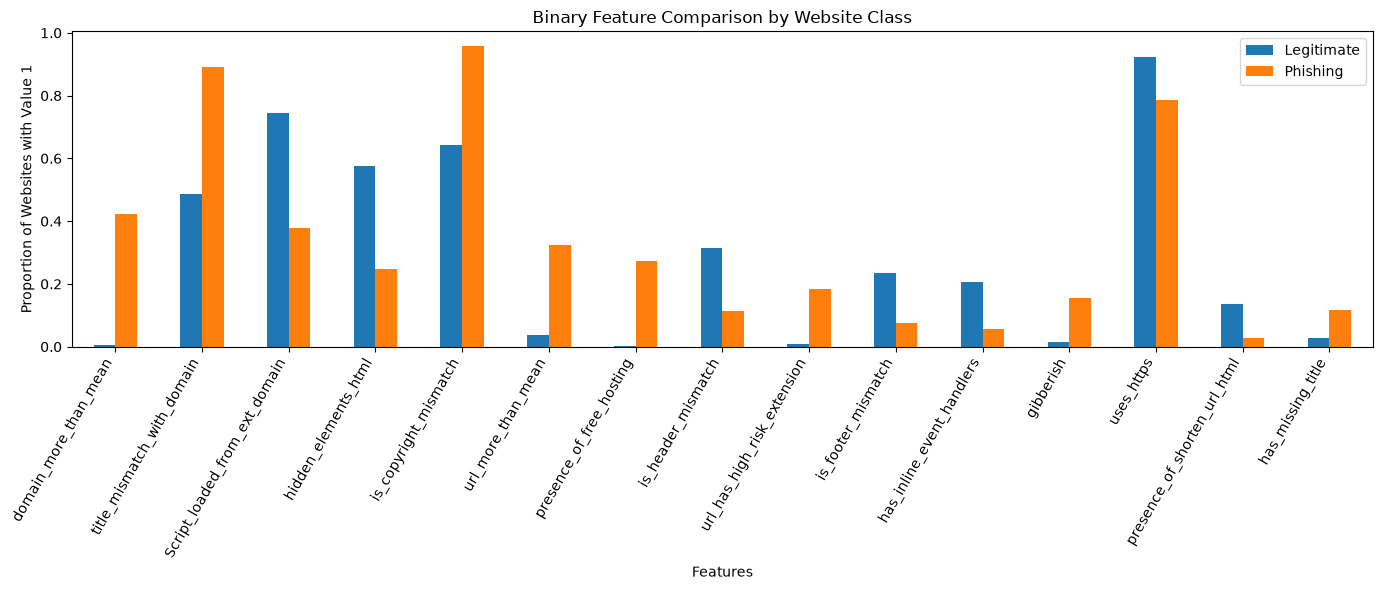

In [29]:
#Visualize binary feature differences
top_binary = binary_class_comparison.head(15).index

binary_class_comparison.loc[
    top_binary, ["Legitimate", "Phishing"]
].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Binary Feature Comparison by Website Class")
plt.xlabel("Features")
plt.ylabel("Proportion of Websites with Value 1")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "binary_features.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

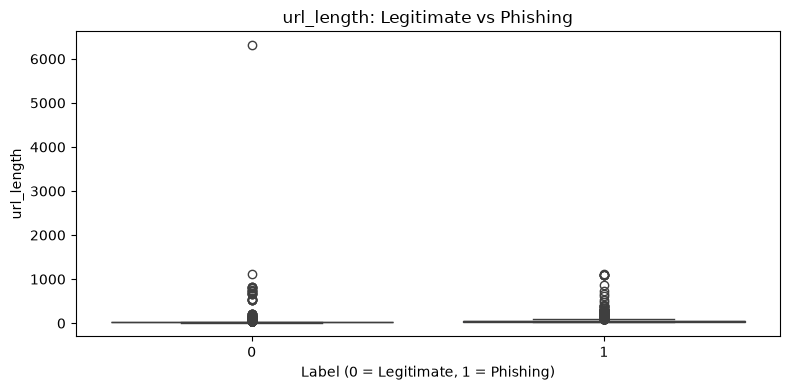

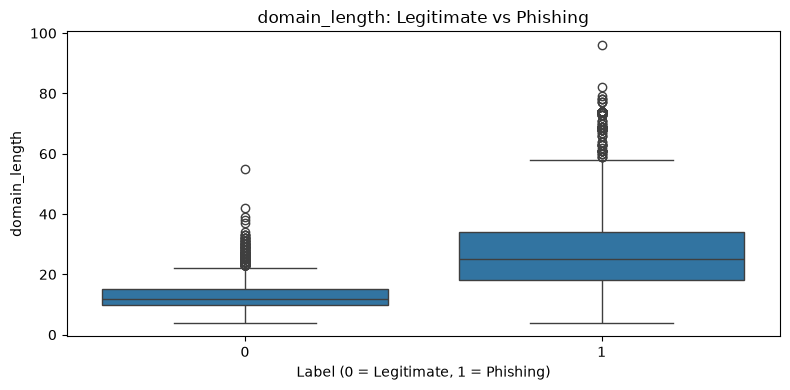

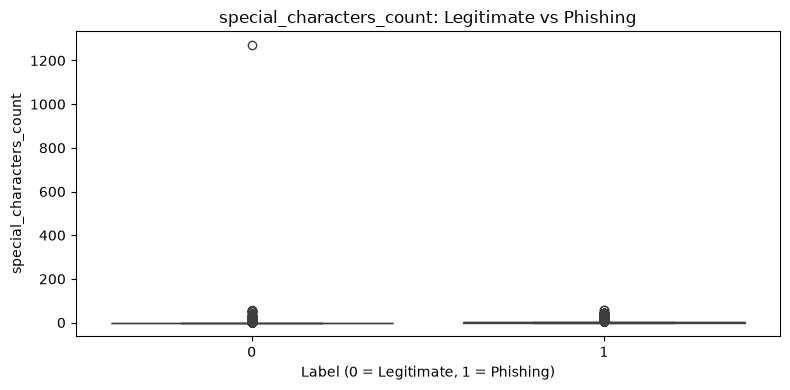

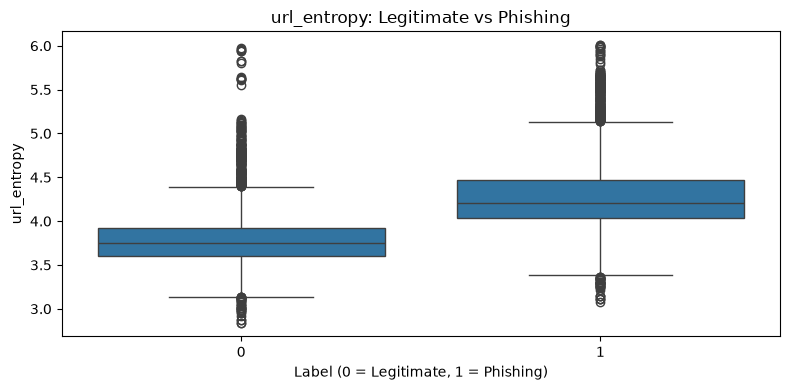

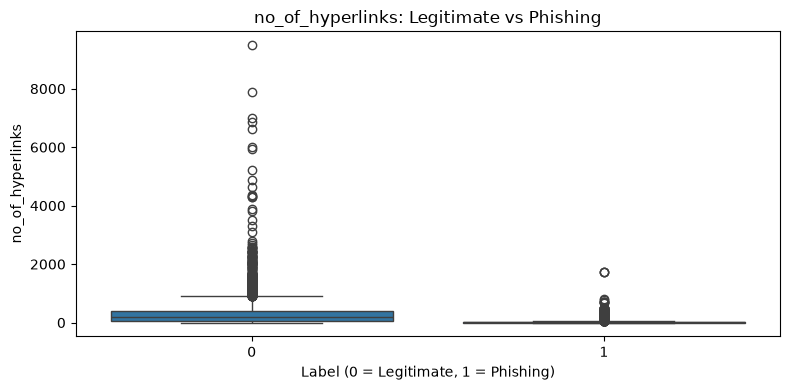

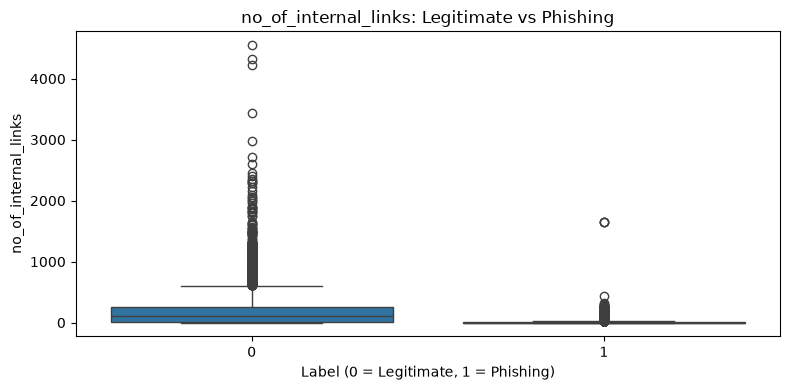

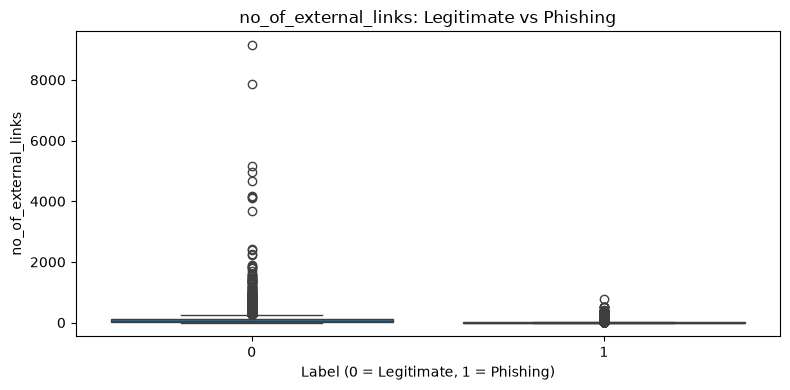

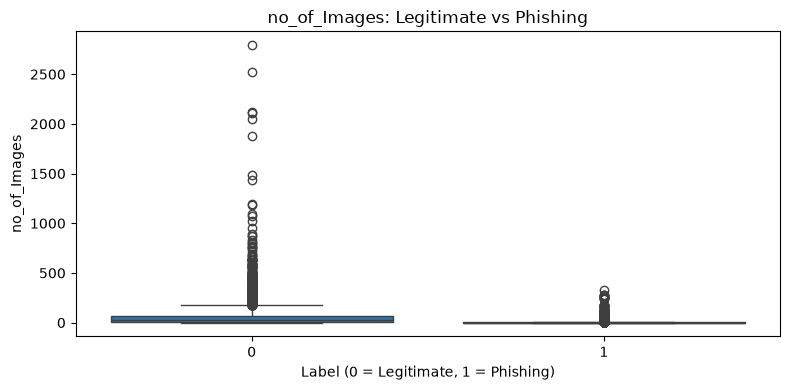

In [30]:
#Investigate numerical feature distributions
selected_features = [
    "url_length",
    "domain_length",
    "special_characters_count",
    "url_entropy",
    "no_of_hyperlinks",
    "no_of_internal_links",
    "no_of_external_links",
    "no_of_Images"
]

for feature in selected_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=features_df,
        x="label",
        y=feature
    )

    plt.title(f"{feature}: Legitimate vs Phishing")
    plt.xlabel("Label (0 = Legitimate, 1 = Phishing)")
    plt.ylabel(feature)

    plt.tight_layout()

    plt.savefig(
        PROJECT_ROOT / "reports" / "figures" / f"{feature}_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [31]:
for feature in selected_features:

    print(f"\n========== {feature} ==========")

    summary = features_df.groupby("label")[feature].describe()

    print(summary)


========== url_length ==========
        count       mean        std   min   25%   50%   75%     max
label                                                              
0      8154.0  29.350135  78.892891  13.0  21.0  24.0  28.0  6310.0
1      7204.0  52.186147  47.156492  16.0  34.0  42.0  59.0  1111.0

========== domain_length ==========
        count       mean        std  min   25%   50%   75%   max
label                                                           
0      8154.0  12.850748   4.296981  4.0  10.0  12.0  15.0  55.0
1      7204.0  26.986396  14.055080  4.0  18.0  25.0  34.0  96.0

========== special_characters_count ==========
        count      mean        std  min  25%  50%  75%     max
label                                                         
0      8154.0  0.575914  14.279187  0.0  0.0  0.0  0.0  1270.0
1      7204.0  1.702110   3.404979  0.0  0.0  1.0  2.0    57.0

========== url_entropy ==========
        count      mean       std       min       25%       50

## 3.3 Outlier Investigation

In [32]:
features_to_check = [
    "url_length",
    "domain_length",
    "special_characters_count",
    "url_entropy",
    "no_of_hyperlinks",
    "no_of_internal_links",
    "no_of_external_links",
    "no_of_Images"
]

for feature in features_to_check:

    print(f"\n{'='*60}")
    print("Feature:", feature)

    extreme_rows = features_df.nlargest(5, feature)[
        ["serial_number", "url", "label", feature]
    ]

    print(extreme_rows.to_string(index=False))


Feature: url_length
 serial_number                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [33]:
outlier_results = []

for feature in features_to_check:

    Q1 = features_df[feature].quantile(0.25)
    Q3 = features_df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = features_df[
        (features_df[feature] < lower_bound) |
        (features_df[feature] > upper_bound)
    ]

    outlier_results.append({
        "Feature": feature,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(features_df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,url_length,-7.000000,73.000000,1373,8.939966
1,domain_length,-8.500000,43.500000,543,3.535617
2,special_characters_count,-1.500000,2.500000,1710,11.134262
3,url_entropy,2.977437,4.965802,397,2.584972
4,no_of_hyperlinks,-324.500000,551.500000,1136,7.396796
5,no_of_internal_links,-187.500000,312.500000,1463,9.525980
6,no_of_external_links,-87.500000,148.500000,1645,10.711030
7,no_of_Images,-49.500000,82.500000,2004,13.048574


In [34]:
for feature in features_to_check:

    Q1 = features_df[feature].quantile(0.25)
    Q3 = features_df[feature].quantile(0.75)

    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    outliers = features_df[
        features_df[feature] > upper_bound
    ]

    print(f"\n{feature}")
    print(outliers["label"].value_counts().rename({
        0: "Legitimate",
        1: "Phishing"
    }))


url_length
label
Phishing      1227
Legitimate     146
Name: count, dtype: int64

domain_length
label
Phishing      542
Legitimate      1
Name: count, dtype: int64

special_characters_count
label
Phishing      1403
Legitimate     307
Name: count, dtype: int64

url_entropy
label
Phishing      347
Legitimate     42
Name: count, dtype: int64

no_of_hyperlinks
label
Legitimate    1126
Phishing        10
Name: count, dtype: int64

no_of_internal_links
label
Legitimate    1458
Phishing         5
Name: count, dtype: int64

no_of_external_links
label
Legitimate    1496
Phishing       149
Name: count, dtype: int64

no_of_Images
label
Legitimate    1734
Phishing       270
Name: count, dtype: int64


In [35]:
complete_summary = features_df.groupby("label")[
    features_to_check
].describe()

complete_summary.to_csv(
    PROJECT_ROOT / "reports" / "numerical_feature_summary.csv"
)

print("Complete numerical summary saved successfully!")

Complete numerical summary saved successfully!


## Investigate the suspicious records

In [ ]:
# Inspect legitimate extreme URLs
legitimate_extremes = features_df[
    (features_df["label"] == 0) &
    (
        (features_df["url_length"] > 200) |
        (features_df["special_characters_count"] > 100)
    )
]

print("Number of suspicious legitimate records:",
      len(legitimate_extremes))

print(
    legitimate_extremes[
        [
            "serial_number",
            "url",
            "url_length",
            "special_characters_count",
            "label"
        ]
    ].head(15).to_string(index=False)
)

Number of suspicious legitimate records: 26
 serial_number                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [37]:
#Check whether calculated URL lengths match actual URL text
features_df["actual_url_length"] = features_df["url"].str.len()

features_df["url_length_difference"] = (
    features_df["url_length"] -
    features_df["actual_url_length"]
)

mismatched_urls = features_df[
    features_df["url_length_difference"] != 0
]

print("URL length mismatches:", len(mismatched_urls))

mismatched_urls[
    [
        "serial_number",
        "url",
        "url_length",
        "actual_url_length",
        "url_length_difference"
    ]
].head(10)

URL length mismatches: 0


,serial_number,url,url_length,actual_url_length,url_length_difference


In [38]:
# check duplicate URLs
duplicate_urls = features_df[
    features_df.duplicated(subset=["url"], keep=False)
].sort_values("url")

print("Rows involved in duplicate URLs:", len(duplicate_urls))

print(
    duplicate_urls[
        ["serial_number", "url", "label"]
    ].head(20).to_string(index=False)
)

Rows involved in duplicate URLs: 14
 serial_number                                                                                 url  label
         18900 https://bafybeig5ip7obxeemkkujlwtwn6xe2azcj2xh453eysnkju36op444cnme.ipfs.dweb.link/      1
  202420263204 https://bafybeig5ip7obxeemkkujlwtwn6xe2azcj2xh453eysnkju36op444cnme.ipfs.dweb.link/      1
  202420256702      https://calendar-invites.com/landing/form/107fab35-6fd3-4df9-afba-148e7ba128a2      1
  202420263361      https://calendar-invites.com/landing/form/107fab35-6fd3-4df9-afba-148e7ba128a2      1
  202420256787                                  https://demo.zerotheme.ir/peak/back/plalala/Sites/      1
  202420263314                                  https://demo.zerotheme.ir/peak/back/plalala/Sites/      1
  202420256786                              https://flotek.com.np/verify.plala.jp/Sites/index.html      1
  202420263313                              https://flotek.com.np/verify.plala.jp/Sites/index.html      1
  20242025

In [40]:
print("URL length mismatches:", len(mismatched_urls))

URL length mismatches: 0


In [41]:
mismatched_urls[
    [
        "serial_number",
        "url_length",
        "actual_url_length",
        "url_length_difference"
    ]
].head(10)

,serial_number,url_length,actual_url_length,url_length_difference


In [42]:
row = features_df.loc[
    features_df["serial_number"] == 202420255975
]

print("Recorded special characters:",
      row["special_characters_count"].iloc[0])

print("Actual URL length:",
      row["url"].str.len().iloc[0])

print("URL:")
print(row["url"].iloc[0])

Recorded special characters: 1270
Actual URL length: 6310
URL:
https://www.lifehacker.jp/?user=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(93)%3E&user_id=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(94)%3E&update=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(95)%3E&view=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(96)%3E&var=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(97)%3E&vis=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(98)%3E&wp=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(99)%3E&where=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(100)%3E&buy=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(101)%3E&site=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(102)%3E&utm_source=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(103)%3E&order=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(104)%3E&username=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(105)%3E&password=%27%3E%22%3E%3C%2fscript%3E%3Csvg%2fonload=confirm(106)%3E&name=

In [43]:
# Special character calculation check
from urllib.parse import urlparse

url = features_df.loc[
    features_df["serial_number"] == 202420255975,
    "url"
].iloc[0]

# Count common special characters directly
special_chars = "!@#$%^&*()-_=+[]{}|;:',.<>?/\\`~"

actual_special_count = sum(
    url.count(char) for char in special_chars
)

print("Actual special-character count:", actual_special_count)

print(
    "Dataset special-character count:",
    features_df.loc[
        features_df["serial_number"] == 202420255975,
        "special_characters_count"
    ].iloc[0]
)

Actual special-character count: 1470
Dataset special-character count: 1270


In [44]:
dictionary_df[
    dictionary_df.astype(str)
    .apply(lambda col: col.str.contains(
        "special_characters_count",
        case=False,
        na=False
    ))
    .any(axis=1)
].to_string(index=False)

"Feature ID             Feature Name               Data Type  Category                                   Description                                                                               Computational Rule/Threshold/Criteria  Values for the sample URL:https://amazon-login.example.test/account/netflix/verify?id=123 Unnamed: 7\n       F₁₄ special_characters_count Numerical (count-based) URL-based Total number of special characters in the URL Number of special characters within the specified list of ('@', ',', '$', '%20', '&', '=', '%', '?', '_', '-', ';')                                                                                        3.0        NaN"

In [45]:
url = features_df.loc[
    features_df["serial_number"] == 202420255975,
    "url"
].iloc[0]

specified_chars = (
    '@', ',', '$', '%20', '&', '=', '%', '?', '_', '-', ';'
)

actual_count = sum(url.count(char) for char in specified_chars)

dataset_count = features_df.loc[
    features_df["serial_number"] == 202420255975,
    "special_characters_count"
].iloc[0]

print("Count using dictionary rule:", actual_count)
print("Dataset recorded count:", dataset_count)
print("Difference:", actual_count - dataset_count)

Count using dictionary rule: 1270
Dataset recorded count: 1270
Difference: 0


In [46]:
# investigate data leakage
dictionary_df[
    dictionary_df["Feature Name"].isin([
        "url_more_than_mean",
        "domain_more_than_mean"
    ])
][
    [
        "Feature Name",
        "Description",
        "Computational Rule/Threshold/Criteria"
    ]
].to_string(index=False)

'         Feature Name                                                Description                                                                  Computational Rule/Threshold/Criteria\n   url_more_than_mean       URL length greater than mean length of phishing URLs       Mean length of all the phishing urls is computed. Value returned in 1 if the url length is more \ndomain_more_than_mean Domain length greater than mean length of phishing domains Mean length of all the phishing domains is computed. Value returned in 1 if the domain length is more '

In [47]:
feature_columns = [
    col for col in features_df.columns
    if col not in ["serial_number", "url", "label"]
]

duplicate_features = features_df[
    features_df.duplicated(
        subset=feature_columns,
        keep=False
    )
].sort_values(feature_columns)

print("Rows with identical feature vectors:",
      len(duplicate_features))

print("\nLabel distribution among these rows:")
print(duplicate_features["label"].value_counts())

print("\nConflicting feature-vector groups:")
conflicts = (
    duplicate_features.groupby(feature_columns)["label"]
    .nunique()
)

print("Groups with conflicting labels:", (conflicts > 1).sum())

Rows with identical feature vectors: 623

Label distribution among these rows:
label
1    401
0    222
Name: count, dtype: int64

Conflicting feature-vector groups:
Groups with conflicting labels: 2


In [48]:
conflicting_groups = conflicts[conflicts > 1].index

conflicting_records = duplicate_features[
    duplicate_features.set_index(feature_columns).index.isin(
        conflicting_groups
    )
]

print(
    conflicting_records[
        ["serial_number", "url", "label"]
    ].to_string(index=False)
)

 serial_number                       url  label
           500          http://fiuxy.co/      0
           873          http://biqle.ru/      0
  202420256519          http://kmwqa.cn/      1
  202420250687 https://www.uxuanhot.com/      1
  202420251540 https://www.tuasaude.com/      0
  202420251726 https://www.firstcry.com/      0
  202420253916 https://www.sbnation.com/      0
  202420253989 https://www.proquest.com/      0
  202420254751 https://www.philstar.com/      0
  202420254771 https://www.etonline.com/      0


In [49]:
conflict_summary = (
    duplicate_features
    .groupby(feature_columns)
    .agg(
        total_records=("label", "size"),
        unique_labels=("label", "nunique"),
        urls=("url", lambda x: list(x)),
        labels=("label", lambda x: list(x))
    )
    .reset_index()
)

conflict_summary = conflict_summary[
    conflict_summary["unique_labels"] > 1
]

for i, row in conflict_summary.iterrows():
    print("\nConflicting group:")
    print("Total records:", row["total_records"])
    print("URLs:", row["urls"])
    print("Labels:", row["labels"])


Conflicting group:
Total records: 3
URLs: ['http://fiuxy.co/', 'http://biqle.ru/', 'http://kmwqa.cn/']
Labels: [0, 0, 1]

Conflicting group:
Total records: 7
URLs: ['https://www.uxuanhot.com/', 'https://www.tuasaude.com/', 'https://www.firstcry.com/', 'https://www.sbnation.com/', 'https://www.proquest.com/', 'https://www.philstar.com/', 'https://www.etonline.com/']
Labels: [1, 0, 0, 0, 0, 0, 0]


In [50]:
duplicate_summary = (
    duplicate_features
    .groupby(feature_columns)
    .agg(
        total_records=("label", "size"),
        unique_urls=("url", "nunique"),
        unique_labels=("label", "nunique")
    )
)

print("Repeated feature-vector groups:",
      len(duplicate_summary))

print("\nGroups containing different URLs:",
      (duplicate_summary["unique_urls"] > 1).sum())

print("\nGroups containing identical URLs:",
      (duplicate_summary["unique_urls"] == 1).sum())

print("\nGroups with conflicting labels:",
      (duplicate_summary["unique_labels"] > 1).sum())

Repeated feature-vector groups: 261

Groups containing different URLs: 256

Groups containing identical URLs: 5

Groups with conflicting labels: 2


In [51]:
feature_columns = [
    col for col in features_df.columns
    if col not in ["serial_number", "url", "label"]
]

constant_features = [
    col for col in feature_columns
    if features_df[col].nunique() <= 1
]

print("Constant features:", len(constant_features))
print(constant_features)

Constant features: 2
['brand_subdomain', 'url_length_difference']


In [52]:
excluded_features = [
    "brand_subdomain",
    "url_more_than_mean",
    "domain_more_than_mean",
    "url_length_difference",
    "actual_url_length",
    "serial_number",
    "url",
    "label"
]

final_feature_columns = [
    col for col in features_df.columns
    if col not in excluded_features
]

print("Original columns:", len(features_df.columns))
print("Final predictive features:", len(final_feature_columns))
print("\nRemaining features:")
print(final_feature_columns)

Original columns: 75
Final predictive features: 67

Remaining features:
['brand_substring_domain', 'brand_typo_dom', 'fake_tld', 'brand_in_path_query', 'dots_path', 'gibberish', 'domain_length', 'url_length', 'url_contains_ip', 'presence_of_url_shortner', 'special_characters_count', 'no_of_at', 'no_of_comma', 'no_of_dollar', 'no_of_semicolon', 'no_of_space', 'no_of_ampersand', 'no_of_dots', 'no_of_equal', 'no_of_percent', 'no_of_underscore', 'no_of_hyphen', 'no_of_questionmark', 'no_of_colon', 'no_of_slashes_inpath', 'has_asterisk', 'has_or', 'has_embedded_url', 'uses_https', 'num_query_params', 'numeric_proportion', 'url_entropy', 'hostname_digit_ratio', 'has_redirections', 'has_punycode', 'count_www', 'count_com', 'url_has_high_risk_extension', 'has_explicit_port', 'total_words_url', 'average_length_of_words', 'longest_word_length', 'shortest_word_length', 'presence_of_free_hosting', 'no_of_forms', 'no_of_Images', 'no_of_hyperlinks', 'no_of_external_links', 'no_of_internal_links', 'n

In [53]:
model_df = features_df.copy()

X = model_df[final_feature_columns].copy()
y = model_df["label"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15358, 67)
y shape: (15358,)


In [54]:
print("Missing values in X:", X.isnull().sum().sum())

print("\nData types:")
print(X.dtypes.value_counts())

print("\nInfinite values:", 
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

Missing values in X: 0

Data types:
int64      62
float64     5
Name: count, dtype: int64

Infinite values: 0


In [55]:
print("Original records:", len(model_df))

print("Duplicate URL rows:",
      model_df.duplicated(subset=["url"]).sum())

print("Unique URLs:",
      model_df["url"].nunique())

Original records: 15358
Duplicate URL rows: 7
Unique URLs: 15351


## Clean exact duplicate URLs

In [56]:
# Remove exact duplicate URLs, keeping the first occurrence
clean_df = model_df.drop_duplicates(
    subset=["url"],
    keep="first"
).copy()

print("Records before cleaning:", len(model_df))
print("Records after cleaning:", len(clean_df))
print("Removed records:", len(model_df) - len(clean_df))

print("\nTarget distribution after cleaning:")
print(clean_df["label"].value_counts())

Records before cleaning: 15358
Records after cleaning: 15351
Removed records: 7

Target distribution after cleaning:
label
0    8154
1    7197
Name: count, dtype: int64


In [57]:
#Prepare X and y again
X_clean = clean_df[final_feature_columns].copy()
y_clean = clean_df["label"].copy()

print("X shape:", X_clean.shape)
print("y shape:", y_clean.shape)

X shape: (15351, 67)
y shape: (15351,)


In [58]:
from sklearn.model_selection import GroupShuffleSplit

groups = (
    X_clean
    .astype(str)
    .agg("|".join, axis=1)
)

print("Total records:", len(X_clean))
print("Unique feature groups:", groups.nunique())

Total records: 15351
Unique feature groups: 14993


## 80/20 group-aware split

In [59]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_clean, y_clean, groups=groups)
)

X_train = X_clean.iloc[train_idx]
X_test = X_clean.iloc[test_idx]

y_train = y_clean.iloc[train_idx]
y_test = y_clean.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training records: 12294
Testing records: 3057

Training distribution:
label
0    6530
1    5764
Name: count, dtype: int64

Testing distribution:
label
0    1624
1    1433
Name: count, dtype: int64


In [60]:
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Overlapping feature groups:",
      len(train_groups.intersection(test_groups)))

Overlapping feature groups: 0


In [61]:
import os

os.makedirs("processed_data", exist_ok=True)

X_train.to_csv("processed_data/X_train.csv", index=False)
X_test.to_csv("processed_data/X_test.csv", index=False)

y_train.to_csv("processed_data/y_train.csv", index=False)
y_test.to_csv("processed_data/y_test.csv", index=False)

print("Training and testing datasets saved successfully.")

Training and testing datasets saved successfully.
